In [2]:
#匯入套件與設定中繼資料
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm, shapiro
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from IPython.display import display, HTML, Image

# ---------------------------------------------------------
# 檔案路徑：預設 CSV 與 Notebook 放在同一資料夾
# ---------------------------------------------------------
BASE_DIR = Path(".")
MSA_FILE = BASE_DIR / "msa_synthetic_data.csv"
PROCESS_FILE = BASE_DIR / "process_synthetic_data.csv"

# ---------------------------------------------------------
# 製程中繼資料：請依實際案例修改
# ---------------------------------------------------------
META = {
    "characteristic": "軸徑",
    "unit": "mm",
    "LSL": 19.900,
    "USL": 20.100,
    "target": 20.000,
    "measurement_system_id": "GAGE-DEMO-01",
    "data_version": "teaching-demo-1.0",
    "data_source": "Python亂數產生的模擬資料",
}

# ---------------------------------------------------------
# 教學用分析設定；不是通用驗收標準
# ---------------------------------------------------------
MSA_MAX_PCT_TOLERANCE = 30.0
MSA_MIN_NDC = 5
MIN_SUBGROUPS = 20
BOOTSTRAP_REPS = 1000
RANDOM_SEED = 2026

# X-bar / R 常數：本範例要求子組大小 n=4
A2 = 0.729
D3 = 0.000
D4 = 2.282
d2 = 2.059

rng = np.random.default_rng(RANDOM_SEED)

errors = []
warnings_list = []
decisions = []

In [3]:
def sha256_file(path):
    """計算輸入檔案的 SHA-256，供追溯使用。"""
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(65536), b""):
            digest.update(block)
    return digest.hexdigest()


def check_unit(df, dataset_name):
    """
    前一版模擬 CSV 沒有 unit 欄。
    此處依 META 的單位宣告，但提醒使用者確認原始資料單位。
    """
    if "unit" not in df.columns:
        warnings_list.append(
            f"{dataset_name} 缺少 unit 欄；"
            f"本次依中繼資料宣告單位為 {META['unit']}，請確認原始資料。"
        )
        return

    units = df["unit"].dropna().astype(str).str.strip().unique()

    if len(units) == 0:
        errors.append(f"{dataset_name} 的 unit 欄沒有有效值。")
    elif len(units) > 1:
        errors.append(f"{dataset_name} 出現多種單位：{units.tolist()}")
    elif units[0] != META["unit"]:
        errors.append(
            f"{dataset_name} 單位為 {units[0]}，"
            f"但中繼資料設定為 {META['unit']}。"
        )


def require_file(path):
    if not path.exists():
        raise FileNotFoundError(
            f"找不到 {path.resolve()}。"
            "請先執行前一個範例產生 CSV，並確認檔案與 Notebook 位於同一資料夾。"
        )


require_file(MSA_FILE)
require_file(PROCESS_FILE)

msa = pd.read_csv(MSA_FILE)
process = pd.read_csv(PROCESS_FILE)

print("MSA 資料預覽")
display(msa.head())

print("製程資料預覽")
display(process.head())

print("MSA 欄位：", msa.columns.tolist())
print("製程資料欄位：", process.columns.tolist())

check_unit(msa, "MSA 資料")
check_unit(process, "製程資料")

# MSA 必要欄位
msa_required = {"part", "operator", "repeat", "measurement"}
missing = msa_required - set(msa.columns)

if missing:
    errors.append(f"MSA 缺少欄位：{sorted(missing)}")
else:
    msa["measurement"] = pd.to_numeric(msa["measurement"], errors="coerce")

    if msa[list(msa_required)].isna().any().any():
        errors.append("MSA 必要欄位有缺值或非數值資料。")

    duplicated_msa = msa.duplicated(
        subset=["part", "operator", "repeat"],
        keep=False
    )
    if duplicated_msa.any():
        errors.append(
            f"MSA 有 {duplicated_msa.sum()} 筆重複的 "
            "part/operator/repeat 組合。"
        )

    # 檢查平衡交叉設計
    counts = msa.groupby(["part", "operator"], observed=True).size()

    if counts.nunique() != 1:
        errors.append("MSA 不是平衡交叉設計：不同組合的重複數不一致。")

    if not counts.empty and counts.iloc[0] < 2:
        errors.append("每個零件 × 作業員組合至少需有 2 次量測。")


# 製程資料必要欄位
process_required = {"subgroup", "measurement"}
missing = process_required - set(process.columns)

if missing:
    errors.append(f"製程資料缺少欄位：{sorted(missing)}")
else:
    process["measurement"] = pd.to_numeric(
        process["measurement"], errors="coerce"
    )

    if process[list(process_required)].isna().any().any():
        errors.append("製程資料的 subgroup 或 measurement 有缺值。")

    if "timestamp" not in process.columns:
        warnings_list.append(
            "製程資料沒有 timestamp 欄；本次只能按子組順序檢查，"
            "無法依實際時間、班別或批次追溯。"
        )

    for col in ["machine_id", "batch_id"]:
        if col not in process.columns:
            warnings_list.append(
                f"製程資料沒有 {col} 欄；無法比較不同機台或批次。"
            )


# 檢查規格設定
if META["LSL"] >= META["USL"]:
    errors.append("規格設定錯誤：LSL 必須小於 USL。")

if not errors:
    print("資料檢核：未發現阻止分析的錯誤。")
else:
    print("資料檢核：發現錯誤，後續分析應停止。")

print("\n警告：")
for item in warnings_list:
    print(" -", item)

print("\n錯誤：")
for item in errors:
    print(" -", item)


MSA 資料預覽


,part,operator,repeat,measurement,run_order
0,P08,C,1,20.039601,1
1,P03,B,1,19.962037,2
2,P04,A,2,19.979290,3
3,P06,A,2,20.005144,4
4,P09,A,2,20.053681,5


製程資料預覽


,subgroup,within_subgroup,measurement
0,1,1,20.020584
1,1,2,19.974772
2,1,3,19.977505
3,1,4,19.986932
4,2,1,20.012111


MSA 欄位： ['part', 'operator', 'repeat', 'measurement', 'run_order']
製程資料欄位： ['subgroup', 'within_subgroup', 'measurement']
資料檢核：未發現阻止分析的錯誤。

警告：
 - MSA 資料 缺少 unit 欄；本次依中繼資料宣告單位為 mm，請確認原始資料。
 - 製程資料 缺少 unit 欄；本次依中繼資料宣告單位為 mm，請確認原始資料。
 - 製程資料沒有 timestamp 欄；本次只能按子組順序檢查，無法依實際時間、班別或批次追溯。
 - 製程資料沒有 machine_id 欄；無法比較不同機台或批次。
 - 製程資料沒有 batch_id 欄；無法比較不同機台或批次。

錯誤：


In [6]:
## MSA：交叉式 Gage R&R
#
#本資料採交叉設計：每一個零件都由每一位作業員重複量測。
#
#ANOVA 模型：
#
#Y = 零件效果 + 作業員效果 + 零件×作業員交互作用 + 重複性誤差
#
#本範例使用平衡交叉 ANOVA 的方法矩估計變異成分；若估計結果為負值，教學程式將該變異成分截為 0。
#
#注意：
#- 應同時看變異成分、圖形與量測作業情境。
#- 不要只用 ANOVA 的 p 值判定量測系統可不可用。
#- 本範例的 %Tolerance 與 ndc 門檻是可修改的課堂設定，不是通用驗收標準。


In [9]:
#分析 Gage R&R
if errors:
    raise ValueError(
        "資料檢核未通過，請先修正 Cell 4 列出的錯誤。"
    )


def analyze_crossed_grr(data):
    model = smf.ols(
        "measurement ~ C(part) * C(operator)",
        data=data
    ).fit()

    table = anova_lm(model, typ=2)

    # statsmodels 版本可能提供或不提供 mean_sq；
    # 若未提供，手動以 sum_sq / df 計算。
    if "mean_sq" not in table.columns:
        table["mean_sq"] = table["sum_sq"] / table["df"]

    expected_terms = [
        "C(part)",
        "C(operator)",
        "C(part):C(operator)",
        "Residual",
    ]

    missing_terms = [term for term in expected_terms if term not in table.index]
    if missing_terms:
        raise ValueError(
            "ANOVA 表缺少預期項目："
            f"{missing_terms}\n實際列名稱：{table.index.tolist()}"
        )

    n_parts = data["part"].nunique()
    n_operators = data["operator"].nunique()
    n_repeats = int(
        data.groupby(["part", "operator"], observed=True).size().iloc[0]
    )

    ms_part = table.loc["C(part)", "mean_sq"]
    ms_operator = table.loc["C(operator)", "mean_sq"]
    ms_interaction = table.loc["C(part):C(operator)", "mean_sq"]
    ms_repeatability = table.loc["Residual", "mean_sq"]

    # 平衡交叉 ANOVA 的方法矩估計
    var_repeatability = max(ms_repeatability, 0.0)
    var_interaction = max(
        (ms_interaction - ms_repeatability) / n_repeats,
        0.0
    )
    var_operator = max(
        (ms_operator - ms_interaction) / (n_parts * n_repeats),
        0.0
    )
    var_part = max(
        (ms_part - ms_interaction) / (n_operators * n_repeats),
        0.0
    )

    var_reproducibility = var_operator + var_interaction
    var_grr = var_repeatability + var_reproducibility
    var_total = var_grr + var_part

    sd_repeatability = np.sqrt(var_repeatability)
    sd_operator = np.sqrt(var_operator)
    sd_interaction = np.sqrt(var_interaction)
    sd_grr = np.sqrt(var_grr)
    sd_part = np.sqrt(var_part)
    sd_total = np.sqrt(var_total)

    tolerance = META["USL"] - META["LSL"]

    pct_study = (
        100 * sd_grr / sd_total if sd_total > 0 else np.nan
    )
    pct_tolerance = (
        100 * 6 * sd_grr / tolerance if tolerance > 0 else np.nan
    )
    ndc = (
        int(np.floor(1.41 * sd_part / sd_grr))
        if sd_grr > 0 else 0
    )

    msa_pass = (
        np.isfinite(pct_tolerance)
        and pct_tolerance <= MSA_MAX_PCT_TOLERANCE
        and ndc >= MSA_MIN_NDC
    )

    return {
        "anova": table,
        "model": model,
        "n_parts": n_parts,
        "n_operators": n_operators,
        "n_repeats": n_repeats,
        "sd_repeatability": sd_repeatability,
        "sd_operator": sd_operator,
        "sd_interaction": sd_interaction,
        "sd_grr": sd_grr,
        "sd_part": sd_part,
        "sd_total": sd_total,
        "pct_study": pct_study,
        "pct_tolerance": pct_tolerance,
        "ndc": ndc,
        "msa_pass": bool(msa_pass),
    }


msa_result = analyze_crossed_grr(msa)

print(f"零件數：{msa_result['n_parts']}")
print(f"作業員數：{msa_result['n_operators']}")
print(f"每組重複數：{msa_result['n_repeats']}")
print(f"重複性 SD：{msa_result['sd_repeatability']:.6f} {META['unit']}")
print(f"作業員變異 SD：{msa_result['sd_operator']:.6f} {META['unit']}")
print(f"交互作用 SD：{msa_result['sd_interaction']:.6f} {META['unit']}")
print(f"Gage R&R SD：{msa_result['sd_grr']:.6f} {META['unit']}")
print(f"%Study Variation：{msa_result['pct_study']:.2f}%")
print(f"%Tolerance：{msa_result['pct_tolerance']:.2f}%")
print(f"ndc：{msa_result['ndc']}")
print("教學用 MSA 閘門：", "通過" if msa_result["msa_pass"] else "未通過")

print("\nANOVA 表")
display(msa_result["anova"].round(6))


零件數：10
作業員數：3
每組重複數：2
重複性 SD：0.001216 mm
作業員變異 SD：0.000625 mm
交互作用 SD：0.000532 mm
Gage R&R SD：0.001467 mm
%Study Variation：3.12%
%Tolerance：4.40%
ndc：45
教學用 MSA 閘門： 通過

ANOVA 表


,sum_sq,df,F,PR(>F),mean_sq
C(part),0.119041,9.0,8946.248739,0.000000,0.013227
C(operator),0.000020,2.0,6.661866,0.004036,0.000010
C(part):C(operator),0.000037,18.0,1.382707,0.210570,0.000002
Residual,0.000044,30.0,NaN,NaN,0.000001


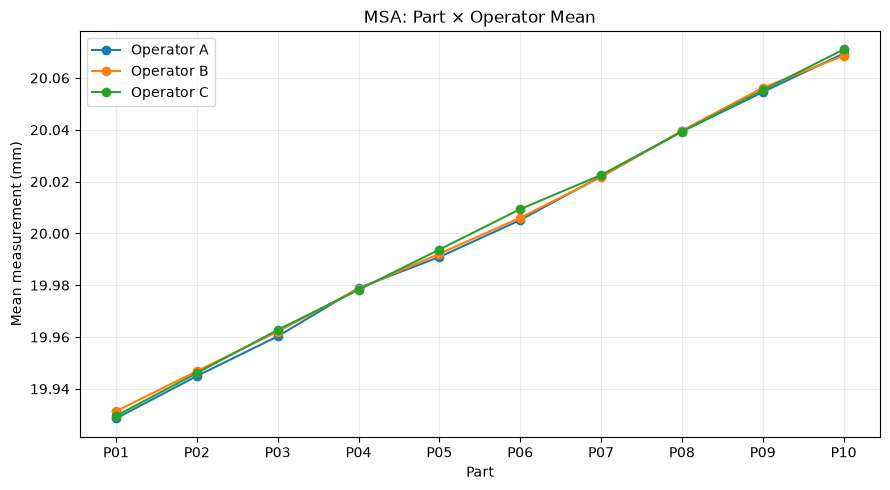

決策：MSA 通過教學用閘門，可繼續檢查製程穩定性。


In [10]:
#MSA 互動圖與分析閘門
means = (
    msa.groupby(["part", "operator"], observed=True)["measurement"]
    .mean()
    .unstack("operator")
)

fig, ax = plt.subplots(figsize=(9, 5))

for operator in means.columns:
    ax.plot(
        means.index.astype(str),
        means[operator],
        marker="o",
        label=f"Operator {operator}"
    )

ax.set_title("MSA: Part × Operator Mean")
ax.set_xlabel("Part")
ax.set_ylabel(f"Mean measurement ({META['unit']})")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

if msa_result["msa_pass"]:
    decisions.append("MSA 通過本 Notebook 設定的教學用閘門。")
    print("決策：MSA 通過教學用閘門，可繼續檢查製程穩定性。")
else:
    decisions.append("MSA 未通過教學用閘門；停止能力分析。")
    print("決策：MSA 未通過教學用閘門，不進行製程能力分析。")


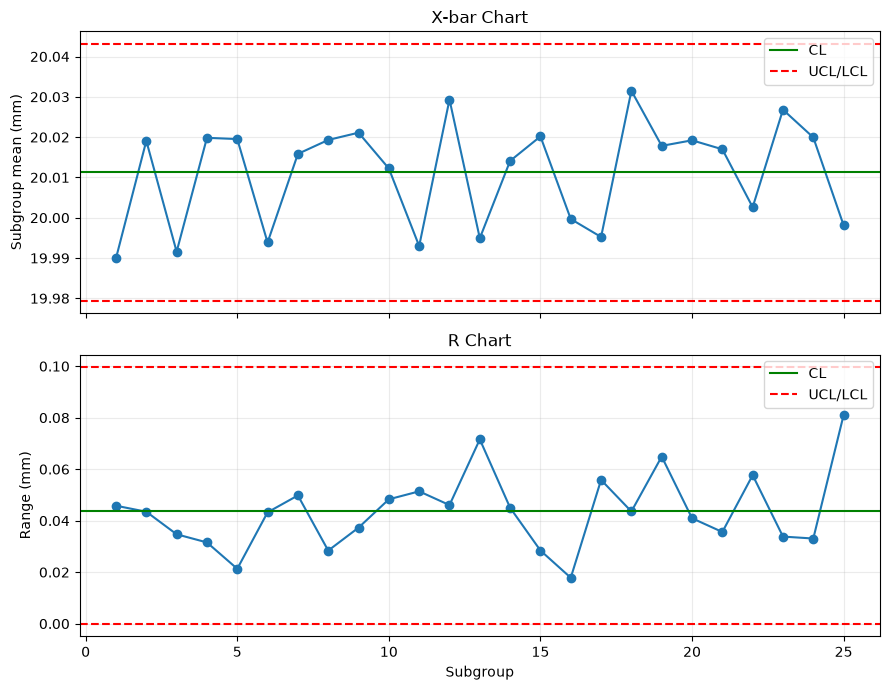

X-bar 圖界外子組： []
R 圖界外子組： []
3-sigma 界限檢查： 未發現界外點


In [11]:
#X-bar / R 管制圖
def analyze_xbar_r(data):
    group_sizes = data.groupby("subgroup", observed=True).size()

    if len(group_sizes) < MIN_SUBGROUPS:
        raise ValueError(
            f"子組數 {len(group_sizes)} 少於設定值 {MIN_SUBGROUPS}。"
        )

    if group_sizes.nunique() != 1:
        raise ValueError("子組大小不一致，不能直接使用本範例的 X-bar/R 常數。")

    subgroup_size = int(group_sizes.iloc[0])

    if subgroup_size != 4:
        raise ValueError(
            f"本 Notebook 範例使用 n=4 的常數，目前每組 n={subgroup_size}。"
        )

    summary = (
        data.groupby("subgroup", observed=True)["measurement"]
        .agg(
            xbar="mean",
            range=lambda x: x.max() - x.min()
        )
        .reset_index()
        .sort_values("subgroup")
    )

    xbarbar = summary["xbar"].mean()
    rbar = summary["range"].mean()

    xbar_ucl = xbarbar + A2 * rbar
    xbar_lcl = xbarbar - A2 * rbar
    r_ucl = D4 * rbar
    r_lcl = D3 * rbar

    xbar_ooc = (
        (summary["xbar"] > xbar_ucl)
        | (summary["xbar"] < xbar_lcl)
    )
    r_ooc = (
        (summary["range"] > r_ucl)
        | (summary["range"] < r_lcl)
    )

    return {
        "summary": summary,
        "subgroup_size": subgroup_size,
        "xbarbar": xbarbar,
        "rbar": rbar,
        "xbar_ucl": xbar_ucl,
        "xbar_lcl": xbar_lcl,
        "r_ucl": r_ucl,
        "r_lcl": r_lcl,
        "xbar_ooc": summary.loc[xbar_ooc, "subgroup"].tolist(),
        "r_ooc": summary.loc[r_ooc, "subgroup"].tolist(),
        "stable_3sigma": not (xbar_ooc.any() or r_ooc.any()),
    }


if msa_result["msa_pass"]:
    control_result = analyze_xbar_r(process)
    s = control_result["summary"]
    x = s["subgroup"]

    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

    axes[0].plot(x, s["xbar"], marker="o")
    axes[0].axhline(control_result["xbarbar"], color="green", label="CL")
    axes[0].axhline(
        control_result["xbar_ucl"], color="red", linestyle="--", label="UCL/LCL"
    )
    axes[0].axhline(
        control_result["xbar_lcl"], color="red", linestyle="--"
    )
    axes[0].set_title("X-bar Chart")
    axes[0].set_ylabel(f"Subgroup mean ({META['unit']})")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(x, s["range"], marker="o")
    axes[1].axhline(control_result["rbar"], color="green", label="CL")
    axes[1].axhline(
        control_result["r_ucl"], color="red", linestyle="--", label="UCL/LCL"
    )
    axes[1].axhline(control_result["r_lcl"], color="red", linestyle="--")
    axes[1].set_title("R Chart")
    axes[1].set_xlabel("Subgroup")
    axes[1].set_ylabel(f"Range ({META['unit']})")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    print("X-bar 圖界外子組：", control_result["xbar_ooc"])
    print("R 圖界外子組：", control_result["r_ooc"])
    print(
        "3-sigma 界限檢查：",
        "未發現界外點"
        if control_result["stable_3sigma"]
        else "發現界外點"
    )
else:
    control_result = None
    print("因 MSA 閘門未通過，跳過管制圖與能力分析。")


In [12]:
#Code：能力指標與 bootstrap 信賴區間
def capability_metrics(values, sigma_within):
    values = np.asarray(values, dtype=float)

    lsl = META["LSL"]
    usl = META["USL"]
    mean = values.mean()
    sigma_overall = values.std(ddof=1)

    if sigma_within <= 0 or sigma_overall <= 0:
        raise ValueError("標準差估計必須大於 0。")

    cp = (usl - lsl) / (6 * sigma_within)
    cpu = (usl - mean) / (3 * sigma_within)
    cpl = (mean - lsl) / (3 * sigma_within)
    cpk = min(cpu, cpl)

    pp = (usl - lsl) / (6 * sigma_overall)
    ppu = (usl - mean) / (3 * sigma_overall)
    ppl = (mean - lsl) / (3 * sigma_overall)
    ppk = min(ppu, ppl)

    # 常態模型下的整體規格外機率估計
    p_below = norm.cdf(lsl, loc=mean, scale=sigma_overall)
    p_above = 1 - norm.cdf(usl, loc=mean, scale=sigma_overall)

    return {
        "mean": mean,
        "sigma_within": sigma_within,
        "sigma_overall": sigma_overall,
        "Cp": cp,
        "Cpu": cpu,
        "Cpl": cpl,
        "Cpk": cpk,
        "Pp": pp,
        "Ppu": ppu,
        "Ppl": ppl,
        "Ppk": ppk,
        "ppm_below_lsl": p_below * 1_000_000,
        "ppm_above_usl": p_above * 1_000_000,
        "ppm_total": (p_below + p_above) * 1_000_000,
    }


def bootstrap_capability(data, reps=1000):
    """
    以子組為單位重抽樣的教學用 percentile bootstrap。
    適用性仍需依資料結構和製程特性確認。
    """
    groups = [
        group["measurement"].to_numpy(dtype=float)
        for _, group in data.groupby("subgroup", observed=True)
    ]

    n_groups = len(groups)
    samples = {"Cp": [], "Cpk": [], "Pp": [], "Ppk": []}

    for _ in range(reps):
        selected = rng.integers(0, n_groups, size=n_groups)
        resampled_groups = [groups[i] for i in selected]
        resampled_values = np.concatenate(resampled_groups)

        resampled_rbar = np.mean([
            group.max() - group.min()
            for group in resampled_groups
        ])
        sigma_within = resampled_rbar / d2

        if sigma_within <= 0:
            continue

        result = capability_metrics(resampled_values, sigma_within)

        for name in samples:
            samples[name].append(result[name])

    intervals = {}
    for name, estimates in samples.items():
        if len(estimates) < reps * 0.5:
            intervals[name] = (np.nan, np.nan)
        else:
            intervals[name] = tuple(
                np.percentile(estimates, [2.5, 97.5])
            )

    return intervals


capability_result = None
capability_ci = None
normality_result = None

if msa_result["msa_pass"] and control_result is not None:
    if not control_result["stable_3sigma"]:
        decisions.append(
            "管制圖發現 3-sigma 界外點；能力分析停止。"
        )
        print("分析閘門：製程有界外點，本次不發布能力結論。")
    else:
        values = process["measurement"].to_numpy(dtype=float)
        sigma_within = control_result["rbar"] / d2

        capability_result = capability_metrics(values, sigma_within)
        capability_ci = bootstrap_capability(
            process,
            reps=BOOTSTRAP_REPS
        )

        # 常態性檢定只作為診斷資訊，不單獨決定分析方法
        if len(values) >= 3:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                normality_result = shapiro(values)

        decisions.append(
            "通過本範例 MSA 與 3-sigma 界限閘門，"
            "計算常態模型能力指標。"
        )

        print("樣本平均：", round(capability_result["mean"], 6))
        print("組內標準差估計：", round(capability_result["sigma_within"], 6))
        print("整體標準差：", round(capability_result["sigma_overall"], 6))
        print("Cp：", round(capability_result["Cp"], 3))
        print("Cpk：", round(capability_result["Cpk"], 3))
        print("Pp：", round(capability_result["Pp"], 3))
        print("Ppk：", round(capability_result["Ppk"], 3))
        print(
            "常態模型預估總不良率（ppm）：",
            round(capability_result["ppm_total"], 2)
        )

        if normality_result is not None:
            print("Shapiro-Wilk p 值：", round(normality_result.pvalue, 5))
            print(
                "提醒：不要只依 Shapiro-Wilk p 值決定分布，"
                "還要看直方圖、機率圖及製程知識。"
            )

        print("\nBootstrap 95% 區間（教學用）")
        display(pd.DataFrame(
            [
                {
                    "指標": name,
                    "下限": interval[0],
                    "上限": interval[1],
                }
                for name, interval in capability_ci.items()
            ]
        ).round(4))
else:
    print("因 MSA 閘門未通過，跳過能力分析。")


樣本平均： 20.011268
組內標準差估計： 0.02119
整體標準差： 0.0218
Cp： 1.573
Cpk： 1.396
Pp： 1.529
Ppk： 1.357
常態模型預估總不良率（ppm）： 23.64
Shapiro-Wilk p 值： 0.52321
提醒：不要只依 Shapiro-Wilk p 值決定分布，還要看直方圖、機率圖及製程知識。

Bootstrap 95% 區間（教學用）


,指標,下限,上限
0,Cp,1.3912,1.8072
1,Cpk,1.2436,1.5820
2,Pp,1.3822,1.7567
3,Ppk,1.2359,1.5306


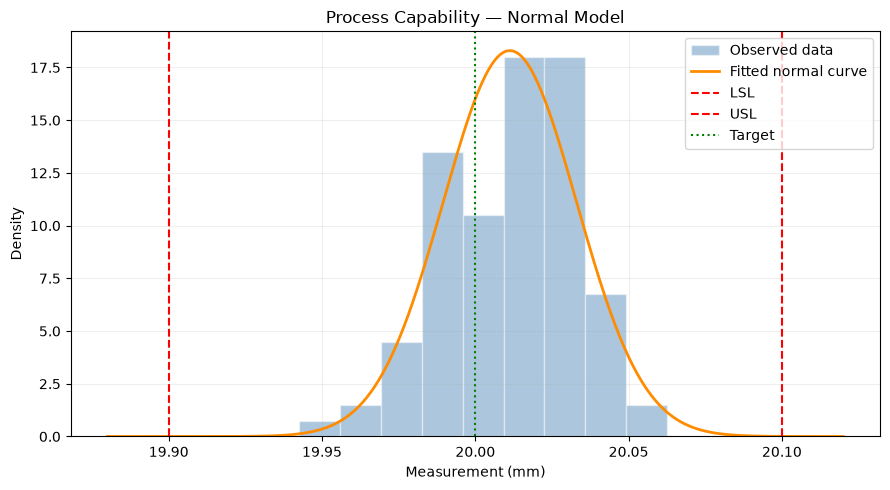

In [13]:
#能力分布圖
if capability_result is not None:
    values = process["measurement"].to_numpy(dtype=float)

    x = np.linspace(
        min(values.min(), META["LSL"]) - 0.02,
        max(values.max(), META["USL"]) + 0.02,
        400
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        values,
        bins="auto",
        density=True,
        alpha=0.45,
        color="steelblue",
        edgecolor="white",
        label="Observed data"
    )

    ax.plot(
        x,
        norm.pdf(
            x,
            capability_result["mean"],
            capability_result["sigma_overall"]
        ),
        color="darkorange",
        linewidth=2,
        label="Fitted normal curve"
    )

    ax.axvline(META["LSL"], color="red", linestyle="--", label="LSL")
    ax.axvline(META["USL"], color="red", linestyle="--", label="USL")
    ax.axvline(META["target"], color="green", linestyle=":", label="Target")

    ax.set_title("Process Capability — Normal Model")
    ax.set_xlabel(f"Measurement ({META['unit']})")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()
else:
    print("沒有能力分析結果，因此不繪製能力分布圖。")


In [14]:
#產生 HTML 報告與追溯紀錄
# 儲存圖表
msa_plot_file = BASE_DIR / "msa_interaction.png"
control_plot_file = BASE_DIR / "control_charts.png"
capability_plot_file = BASE_DIR / "capability.png"

# MSA 圖
means = (
    msa.groupby(["part", "operator"], observed=True)["measurement"]
    .mean()
    .unstack("operator")
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for operator in means.columns:
    ax.plot(
        means.index.astype(str),
        means[operator],
        marker="o",
        label=f"Operator {operator}"
    )
ax.set_title("MSA: Part × Operator Mean")
ax.set_xlabel("Part")
ax.set_ylabel(f"Measurement ({META['unit']})")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(msa_plot_file, dpi=150)
plt.close(fig)

# 管制圖
if control_result is not None:
    s = control_result["summary"]
    x = s["subgroup"]

    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

    axes[0].plot(x, s["xbar"], marker="o")
    axes[0].axhline(control_result["xbarbar"], color="green", label="CL")
    axes[0].axhline(
        control_result["xbar_ucl"], color="red", linestyle="--", label="UCL/LCL"
    )
    axes[0].axhline(
        control_result["xbar_lcl"], color="red", linestyle="--"
    )
    axes[0].set_title("X-bar Chart")
    axes[0].set_ylabel(f"Mean ({META['unit']})")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(x, s["range"], marker="o")
    axes[1].axhline(control_result["rbar"], color="green", label="CL")
    axes[1].axhline(
        control_result["r_ucl"], color="red", linestyle="--", label="UCL/LCL"
    )
    axes[1].axhline(control_result["r_lcl"], color="red", linestyle="--")
    axes[1].set_title("R Chart")
    axes[1].set_xlabel("Subgroup")
    axes[1].set_ylabel(f"Range ({META['unit']})")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    fig.savefig(control_plot_file, dpi=150)
    plt.close(fig)

# 能力圖
if capability_result is not None:
    values = process["measurement"].to_numpy(dtype=float)
    x = np.linspace(
        min(values.min(), META["LSL"]) - 0.02,
        max(values.max(), META["USL"]) + 0.02,
        400
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.hist(
        values,
        bins="auto",
        density=True,
        alpha=0.45,
        edgecolor="white",
        label="Observed data"
    )
    ax.plot(
        x,
        norm.pdf(
            x,
            capability_result["mean"],
            capability_result["sigma_overall"]
        ),
        label="Fitted normal curve"
    )
    ax.axvline(META["LSL"], color="red", linestyle="--", label="LSL")
    ax.axvline(META["USL"], color="red", linestyle="--", label="USL")
    ax.axvline(META["target"], color="green", linestyle=":", label="Target")
    ax.set_title("Capability Plot")
    ax.set_xlabel(f"Measurement ({META['unit']})")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    fig.savefig(capability_plot_file, dpi=150)
    plt.close(fig)


# 建立 HTML 表格
metadata_df = pd.DataFrame(
    [{"欄位": k, "設定值": v} for k, v in META.items()]
)

msa_summary_df = pd.DataFrame([
    ["零件數", msa_result["n_parts"]],
    ["作業員數", msa_result["n_operators"]],
    ["每組重複數", msa_result["n_repeats"]],
    ["Gage R&R SD", msa_result["sd_grr"]],
    ["%Study Variation", msa_result["pct_study"]],
    ["%Tolerance", msa_result["pct_tolerance"]],
    ["ndc", msa_result["ndc"]],
    ["教學用 MSA 閘門", "通過" if msa_result["msa_pass"] else "未通過"],
], columns=["MSA 項目", "結果"])

warning_html = (
    "<ul>" + "".join(f"<li>{w}</li>" for w in warnings_list) + "</ul>"
    if warnings_list else "<p>無警告</p>"
)

decision_html = (
    "<ul>" + "".join(f"<li>{d}</li>" for d in decisions) + "</ul>"
    if decisions else "<p>無分析決策紀錄</p>"
)

if control_result is not None:
    stability_text = (
        "未發現 3-sigma 界外點"
        if control_result["stable_3sigma"]
        else "發現 3-sigma 界外點；能力結論不應直接發布"
    )
    control_html = f"""
    <p>管制圖結果：{stability_text}</p>
    <p>X-bar 圖界外子組：{control_result['xbar_ooc']}</p>
    <p>R 圖界外子組：{control_result['r_ooc']}</p>
    <img src="{control_plot_file.name}" width="850">
    """
else:
    control_html = "<p>管制圖未執行。</p>"

if capability_result is not None:
    capability_df = pd.DataFrame([
        ["平均值", capability_result["mean"]],
        ["組內標準差", capability_result["sigma_within"]],
        ["整體標準差", capability_result["sigma_overall"]],
        ["Cp", capability_result["Cp"]],
        ["Cpk", capability_result["Cpk"]],
        ["Pp", capability_result["Pp"]],
        ["Ppk", capability_result["Ppk"]],
        ["常態模型預估總不良率 (ppm)", capability_result["ppm_total"]],
    ], columns=["項目", "結果"])

    capability_html = f"""
    <p>常態性檢查 p 值：
       {normality_result.pvalue:.5f}
       （若未執行則無資料）</p>
    <p>能力指標信賴區間採用子組重抽樣 bootstrap，
       屬本課程的教學示範方法。</p>
    {capability_df.to_html(index=False, float_format=lambda x: f"{x:.5f}")}
    <img src="{capability_plot_file.name}" width="850">
    """
else:
    capability_html = "<p>能力分析未執行或未發布。</p>"

report_status = (
    "能力分析已完成（教學範例）"
    if capability_result is not None
    else "能力分析未完成或未發布"
)

html = f"""
<!doctype html>
<html lang="zh-Hant">
<head>
<meta charset="utf-8">
<title>SPC / MSA 教學報告</title>
<style>
body {{font-family: Arial, sans-serif; margin: 32px; line-height: 1.6;}}
h1, h2 {{color: #075b70;}}
table {{border-collapse: collapse; margin: 12px 0 24px;}}
th, td {{border: 1px solid #bbb; padding: 7px 10px;}}
th {{background: #e8f2f4;}}
.note {{background: #eef7f7; padding: 12px;}}
.status {{background: #fff2d8; padding: 12px; font-weight: bold;}}
img {{max-width: 100%; height: auto;}}
</style>
</head>
<body>
<h1>SPC / MSA 自動分析報告</h1>
<p class="status">報告狀態：{report_status}</p>
<p>產生時間：{datetime.now(timezone.utc).astimezone().isoformat(timespec="seconds")}</p>

<h2>1. 中繼資料</h2>
{metadata_df.to_html(index=False)}

<h2>2. 資料檢核警告</h2>
{warning_html}

<h2>3. MSA 結果</h2>
{msa_summary_df.to_html(index=False, float_format=lambda x: f"{x:.5f}")}
<p><strong>方法：</strong>平衡交叉設計 ANOVA 方法矩估計。</p>
<img src="{msa_plot_file.name}" width="750">
<h3>ANOVA 表</h3>
{msa_result['anova'].to_html(float_format=lambda x: f"{x:.6g}")}

<h2>4. 製程穩定性</h2>
{control_html}

<h2>5. 製程能力分析</h2>
{capability_html}

<h2>6. 分析決策紀錄</h2>
{decision_html}

<h2>7. 限制與假設</h2>
<div class="note">
本 Notebook 是教學範例。管制圖目前只檢查 3-sigma 界外點，
沒有加入 Nelson／WECO 連續點規則。能力指標採常態模型，
Shapiro-Wilk 檢定 p 值不能單獨證明常態性。
MSA 門檻、樣本需求與能力判定標準需依實際用途及適用規範確認。
本範例的資料沒有時間戳記、機台和批次欄位，因此無法進行相應分層分析。
</div>
</body>
</html>
"""

report_file = BASE_DIR / "spc_msa_report.html"
report_file.write_text(html, encoding="utf-8")

run_log = {
    "run_time_local": datetime.now().astimezone().isoformat(),
    "metadata": META,
    "input_sha256": {
        str(MSA_FILE): sha256_file(MSA_FILE),
        str(PROCESS_FILE): sha256_file(PROCESS_FILE),
    },
    "warnings": warnings_list,
    "decisions": decisions,
    "settings": {
        "msa_max_pct_tolerance": MSA_MAX_PCT_TOLERANCE,
        "msa_min_ndc": MSA_MIN_NDC,
        "min_subgroups": MIN_SUBGROUPS,
        "bootstrap_reps": BOOTSTRAP_REPS,
        "control_chart_rule": "僅檢查 3-sigma 界外點",
        "within_sigma_estimator": "R-bar / d2, n=4",
        "overall_sigma_estimator": "樣本標準差，ddof=1",
    },
    "software_versions": {
        "python": sys.version,
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "statsmodels": statsmodels.__version__,
    },
}

log_file = BASE_DIR / "analysis_log.json"
log_file.write_text(
    json.dumps(run_log, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("已輸出：")
print(" -", report_file.resolve())
print(" -", log_file.resolve())
print(" -", msa_plot_file.resolve())
if control_result is not None:
    print(" -", control_plot_file.resolve())
if capability_result is not None:
    print(" -", capability_plot_file.resolve())


已輸出：
 - D:\python\python_env\AI_new\SPC example\spc_msa_report.html
 - D:\python\python_env\AI_new\SPC example\analysis_log.json
 - D:\python\python_env\AI_new\SPC example\msa_interaction.png
 - D:\python\python_env\AI_new\SPC example\control_charts.png
 - D:\python\python_env\AI_new\SPC example\capability.png


In [15]:
display(HTML(Path("spc_msa_report.html").read_text(encoding="utf-8")))


欄位,設定值
characteristic,軸徑
unit,mm
LSL,19.9
USL,20.1
target,20.0
measurement_system_id,GAGE-DEMO-01
data_version,teaching-demo-1.0
data_source,前一個 Python 範例產生的模擬資料
MSA 項目,結果
零件數,10
